# Advertising Spend vs Product Sales — Multiple Linear Regression

**Assignment:** Task 6 | **Date:** 7 October 2026
**Analyst:** Mohammed Mutee Ruknuddin
**Dataset:** [Advertising Dataset — Kaggle (`ashydv/advertising-dataset`)](https://www.kaggle.com/datasets/ashydv/advertising-dataset)

---

## Business Scenario

A consumer goods company promotes its product through three advertising channels — **Television (TV)**,
**Radio** and **Newspaper**. Management wants an answer to one question:

> *"How do different advertising channels together influence product sales, and can we predict future sales from a planned advertising budget?"*

As the Data Analyst, my job is to quantify the relationship, build a predictive model, and translate the
model into a budget decision the marketing team can act on.

## Objectives

| # | Task |
|---|------|
| 1 | Load the dataset and examine the available columns |
| 2 | Use `TV`, `Radio`, `Newspaper` spends as input features and `Sales` as the target |
| 3 | Build a model that learns the spend → sales relationship |
| 4 | Train the model on historical data |
| 5 | Predict sales for unseen data points |
| 6 | Predict sales for **TV = 150, Radio = 20, Newspaper = 30** |
| 7 | Evaluate the model's prediction error |
| 8 | Interpret coefficients — strongest and weakest advertising medium |
| 9 | Visualise actual sales vs predicted sales |
| 10 | Give one business recommendation and one technical improvement |

**Units:** spends are in thousands of dollars (\$'000) per market; `Sales` is in thousands of units.

## 1. Setup — Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

# Presentation settings
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160,
                     "axes.titlesize": 13, "axes.titleweight": "bold",
                     "figure.autolayout": True})

RANDOM_STATE = 42
VISUALS = "visuals"
os.makedirs(VISUALS, exist_ok=True)

# Save every figure as a PNG so the same visuals can be reused in the PDF report
def save(fig, name):
    fig.savefig(os.path.join(VISUALS, name), bbox_inches="tight")

print("Libraries loaded. Figures will be saved to ./visuals/")

Libraries loaded. Figures will be saved to ./visuals/


## 2. Task 1 — Load the Dataset and Examine the Available Columns

The dataset is the Kaggle **Advertising Dataset** (`ashydv/advertising-dataset`). It was pulled with
`kagglehub.dataset_download("ashydv/advertising-dataset")` and saved next to this notebook as
`advertising.csv`, so the notebook runs offline and reproducibly.

In [2]:
# Source: kagglehub.dataset_download("ashydv/advertising-dataset") -> saved locally as advertising.csv
df = pd.read_csv("advertising.csv")

print(f"Rows: {df.shape[0]}   Columns: {df.shape[1]}")
print(f"Column names: {list(df.columns)}")
df.head(10)

Rows: 200   Columns: 4
Column names: ['TV', 'Radio', 'Newspaper', 'Sales']


,TV,Radio,Newspaper,Sales
0,230.1000,37.8000,69.2000,22.1000
1,44.5000,39.3000,45.1000,10.4000
2,17.2000,45.9000,69.3000,12.0000
3,151.5000,41.3000,58.5000,16.5000
4,180.8000,10.8000,58.4000,17.9000
5,8.7000,48.9000,75.0000,7.2000
6,57.5000,32.8000,23.5000,11.8000
7,120.2000,19.6000,11.6000,13.2000
8,8.6000,2.1000,1.0000,4.8000
9,199.8000,2.6000,21.2000,15.6000


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [4]:
# Data quality checks
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
quality

Duplicate rows: 0


,dtype,non_null,missing,missing_%,unique,min,max
TV,float64,200,0,0.0000,190,0.7000,296.4000
Radio,float64,200,0,0.0000,167,0.0000,49.6000
Newspaper,float64,200,0,0.0000,172,0.3000,114.0000
Sales,float64,200,0,0.0000,121,1.6000,27.0000


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
TV,200.0000,147.0400,85.8500,0.7000,74.3800,149.7500,218.8200,296.4000
Radio,200.0000,23.2600,14.8500,0.0000,9.9800,22.9000,36.5200,49.6000
Newspaper,200.0000,30.5500,21.7800,0.3000,12.7500,25.7500,45.1000,114.0000
Sales,200.0000,15.1300,5.2800,1.6000,11.0000,16.0000,19.0500,27.0000


### Observations — Data Structure & Quality

* The dataset has **200 rows and 4 columns**: `TV`, `Radio`, `Newspaper` (advertising spend per market, in \$'000)
  and `Sales` (units sold, in '000s). Every column is numeric (`float64`), so no encoding is needed.
* **No missing values and no duplicate rows** — the data is clean and usable as-is. No imputation step is required.
* **Spend ranges differ a lot between channels:**
  * `TV` — 0.7 to 296.4, mean ≈ **147.0** → the heaviest-funded channel by a wide margin.
  * `Radio` — 0.0 to 49.6, mean ≈ **23.3**.
  * `Newspaper` — 0.3 to 114.0, mean ≈ **30.5**, but with a long right tail (median 25.8 < mean 30.5).
* **Newspaper receives more average budget (\$30.5k) than Radio (\$23.3k)** — worth keeping in mind, because
  the model will show these two channels are nothing alike in value.
* `Sales` ranges from **1.6 to 27.0** with a mean of **15.13** and standard deviation 5.28 — a well-behaved
  target with no extreme outliers.
* Because TV budgets are roughly 6× larger and far more variable than Radio budgets, raw coefficients alone
  will not tell us which channel matters most in practice. We will therefore also compute
  **standardised coefficients** later.

## 3. Exploratory Data Analysis

Before modelling, we look at how each channel is distributed and how each one moves with `Sales`.

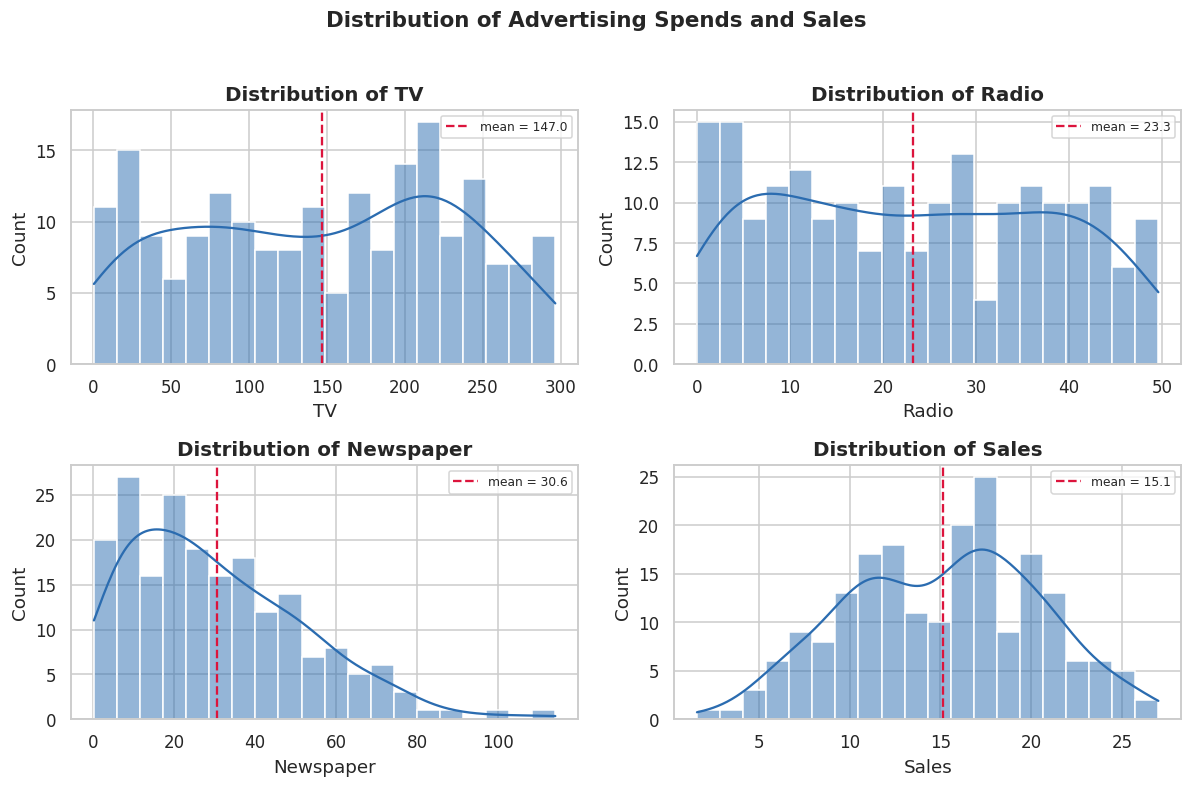

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, bins=20, ax=ax, color="#2b6cb0", edgecolor="white")
    ax.axvline(df[col].mean(), color="crimson", ls="--", lw=1.5, label=f"mean = {df[col].mean():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of Advertising Spends and Sales", fontsize=14, fontweight="bold", y=1.02)
save(fig, "01_distributions.png")
plt.show()

**Observation:** `TV` spend is spread fairly evenly across the whole budget range (close to uniform), `Radio`
is mildly right-skewed, and `Newspaper` is clearly **right-skewed** with a few very high-spend markets
(up to 114). `Sales` is roughly symmetric and centred near 15–16 — a good sign for linear regression, whose
errors are assumed to be approximately symmetric.

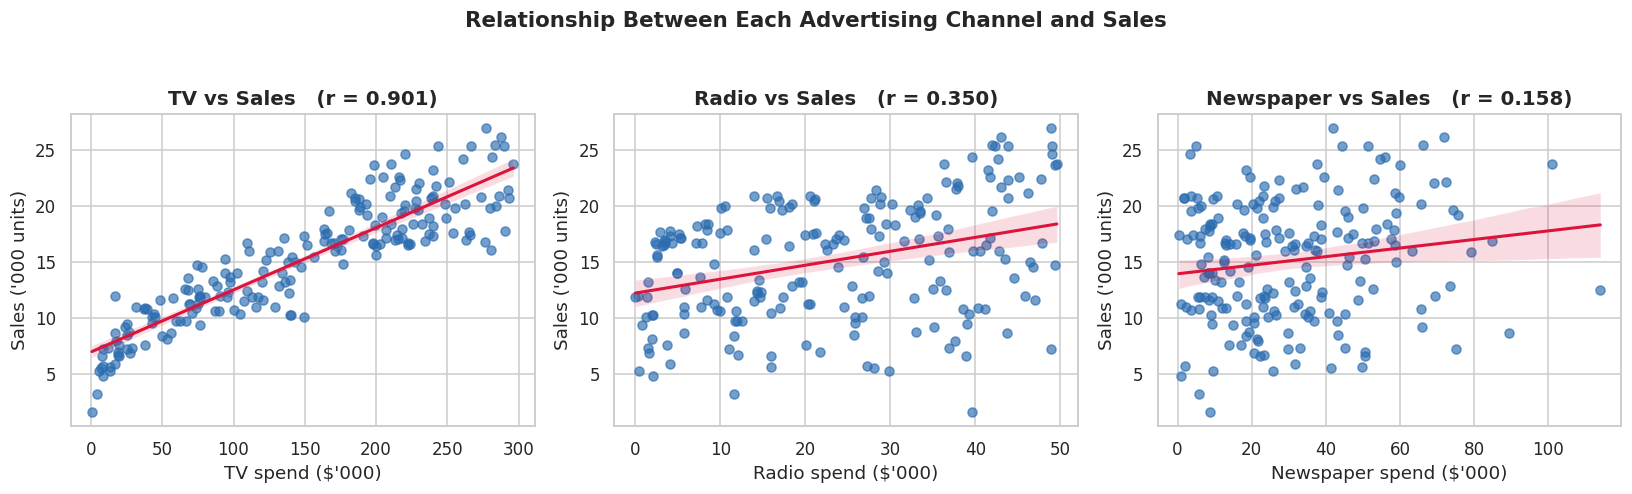

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, ci=95,
                scatter_kws=dict(alpha=0.65, s=35, color="#2b6cb0"),
                line_kws=dict(color="crimson", lw=2))
    r = df[col].corr(df["Sales"])
    ax.set_title(f"{col} vs Sales   (r = {r:.3f})")
    ax.set_xlabel(f"{col} spend ($'000)")
    ax.set_ylabel("Sales ('000 units)")
fig.suptitle("Relationship Between Each Advertising Channel and Sales", fontsize=14, fontweight="bold", y=1.04)
save(fig, "02_scatter_vs_sales.png")
plt.show()

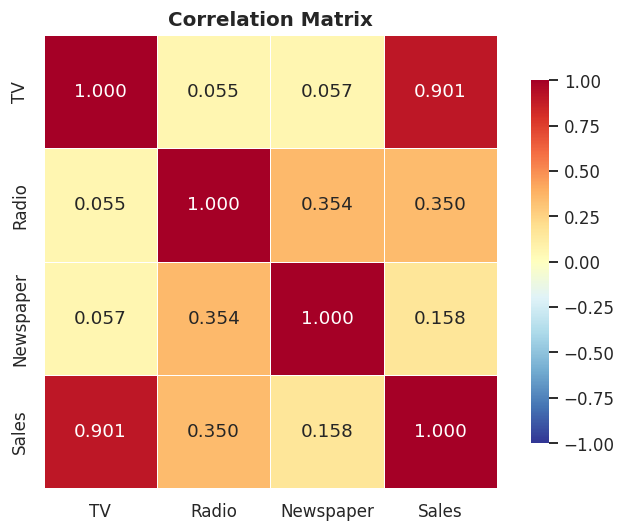

Correlation of each channel with Sales (strongest first):


,corr_with_Sales
TV,0.9012
Radio,0.3496
Newspaper,0.1580


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="RdYlBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix")
save(fig, "03_correlation_heatmap.png")
plt.show()

print("Correlation of each channel with Sales (strongest first):")
df.corr()["Sales"].drop("Sales").sort_values(ascending=False).to_frame("corr_with_Sales")

### Observations — Correlation & Relationships

| Channel | Correlation with Sales | Reading |
|---------|-----------------------|---------|
| **TV** | **0.901** | Very strong, tight and clearly linear — the dominant driver |
| **Radio** | **0.350** | Weak-to-moderate positive; visible but noisy |
| **Newspaper** | **0.158** | Negligible — the scatter is essentially a cloud |

* **TV overwhelmingly dominates.** At r = 0.901 it alone explains about **81%** of sales variation. The
  scatter is tight around the trend line across the whole budget range.
* **Radio shows only a weak overall trend** (r = 0.350). Its scatter is broad — but this understates Radio,
  because the plot ignores TV. Once TV is controlled for in the regression, Radio turns out to be highly
  significant.
* **Newspaper barely tracks sales at all** (r = 0.158). Importantly, `Newspaper` is correlated with `Radio`
  (**r = 0.354**) — markets that spend on radio also tend to spend on newspapers. This hints that Newspaper's
  weak standalone correlation may be **borrowed credit from Radio**, which the regression will separate out.
* Predictor-to-predictor correlation is otherwise low (TV vs Radio r = 0.055), so multicollinearity should
  not destabilise the model. We verify this with VIF below.

In [9]:
# Variance Inflation Factor - confirms predictors are not redundant
features = ["TV", "Radio", "Newspaper"]
vif = []
for col in features:
    others = [c for c in features if c != col]
    r2_aux = LinearRegression().fit(df[others], df[col]).score(df[others], df[col])
    vif.append({"feature": col, "VIF": 1 / (1 - r2_aux)})
pd.DataFrame(vif).set_index("feature").round(3)

,VIF
feature,
TV,1.0050
Radio,1.1450
Newspaper,1.1450


**Observation:** All VIF values are **well below 5** (max ≈ 1.15), so the three spends carry largely
independent information. Their regression coefficients can be interpreted safely.

## 4. Tasks 2 & 3 — Define Features / Target and Build the Model

* **Input features (X):** `TV`, `Radio`, `Newspaper`
* **Target variable (y):** `Sales`

Because the target is continuous and the EDA showed broadly linear relationships, the natural model is
**Multiple Linear Regression**:

$$\widehat{Sales} = eta_0 + eta_1 \cdot TV + eta_2 \cdot Radio + eta_3 \cdot Newspaper$$

It is also the most *explainable* choice — each coefficient is directly readable as a return on spend,
which is exactly what the marketing team needs.

In [10]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Features (X):", list(X.columns), "| shape:", X.shape)
print("Target   (y):", y.name, "| shape:", y.shape)

Features (X): ['TV', 'Radio', 'Newspaper'] | shape: (200, 3)
Target   (y): Sales | shape: (200,)


## 5. Task 4 — Train the Model on Historical Data

We hold back **20% of the markets as unseen test data** so that model error is measured on records the
model never saw during training.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training set : {X_train.shape[0]} rows ({X_train.shape[0]/len(X):.0%})")
print(f"Test set     : {X_test.shape[0]} rows ({X_test.shape[0]/len(X):.0%})")

model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel trained successfully.")
print(f"Intercept (b0): {model.intercept_:.4f}")
for name, coef in zip(X.columns, model.coef_):
    print(f"  Coefficient {name:<10}: {coef:+.5f}")

Training set : 160 rows (80%)
Test set     : 40 rows (20%)

Model trained successfully.
Intercept (b0): 4.7141
  Coefficient TV        : +0.05451
  Coefficient Radio     : +0.10095
  Coefficient Newspaper : +0.00434


In [12]:
equation = (f"Sales = {model.intercept_:.4f} "
            + " ".join(f"{c:+.5f}*{n}" for n, c in zip(X.columns, model.coef_)))
print("Fitted regression equation:\n")
print(" ", equation)

Fitted regression equation:

  Sales = 4.7141 +0.05451*TV +0.10095*Radio +0.00434*Newspaper


## 6. Task 5 — Predict Sales for Unseen Data Points

These 40 test markets were never used in training, so these predictions simulate real forecasting.

In [13]:
y_pred = model.predict(X_test)

comparison = X_test.copy()
comparison["Actual_Sales"] = y_test
comparison["Predicted_Sales"] = y_pred.round(3)
comparison["Error"] = (y_test - y_pred).round(3)
comparison["Abs_%_Error"] = (abs(y_test - y_pred) / y_test * 100).round(2)

print("Predictions on unseen test data (first 15 of 40 markets):")
comparison.head(15)

Predictions on unseen test data (first 15 of 40 markets):


,TV,Radio,Newspaper,Actual_Sales,Predicted_Sales,Error,Abs_%_Error
95,163.3000,31.6000,52.9000,16.9000,17.0350,-0.1350,0.8000
15,195.4000,47.7000,52.9000,22.4000,20.4100,1.9900,8.8900
30,292.9000,28.3000,43.2000,21.4000,23.7240,-2.3240,10.8600
158,11.7000,36.9000,45.2000,7.3000,9.2730,-1.9730,27.0200
128,220.3000,49.0000,3.2000,24.7000,21.6830,3.0170,12.2200
115,75.1000,35.0000,52.7000,12.6000,12.5690,0.0310,0.2400
69,216.8000,43.9000,27.2000,22.3000,21.0810,1.2190,5.4700
170,50.0000,11.6000,18.4000,8.4000,8.6900,-0.2900,3.4600
174,222.4000,3.4000,13.1000,16.5000,17.2370,-0.7370,4.4700
45,175.1000,22.5000,31.5000,16.1000,16.6670,-0.5670,3.5200


In [14]:
print("Where the model is most and least accurate on unseen data:\n")
ranked = comparison.sort_values("Abs_%_Error")
print("5 most accurate predictions")
display(ranked.head(5)[["TV", "Radio", "Newspaper", "Actual_Sales", "Predicted_Sales", "Abs_%_Error"]])
print("5 least accurate predictions")
display(ranked.tail(5)[["TV", "Radio", "Newspaper", "Actual_Sales", "Predicted_Sales", "Abs_%_Error"]])

Where the model is most and least accurate on unseen data:

5 most accurate predictions


,TV,Radio,Newspaper,Actual_Sales,Predicted_Sales,Abs_%_Error
148,38.0000,40.3000,11.9000,10.9000,10.9050,0.0500
115,75.1000,35.0000,52.7000,12.6000,12.5690,0.2400
16,67.8000,36.6000,114.0000,12.5000,12.5990,0.7900
95,163.3000,31.6000,52.9000,16.9000,17.0350,0.8000
93,250.9000,36.5000,72.3000,22.2000,22.3890,0.8500


5 least accurate predictions


,TV,Radio,Newspaper,Actual_Sales,Predicted_Sales,Abs_%_Error
158,11.7000,36.9000,45.2000,7.3000,9.2730,27.0200
150,280.7000,13.9000,37.0000,16.1000,21.5780,34.0300
132,8.4000,27.2000,2.1000,5.7000,7.9270,39.0700
56,7.3000,28.1000,41.4000,5.5000,8.1280,47.7800
78,5.4000,29.9000,9.4000,5.3000,8.0680,52.2200


**Observation:** Predictions track actual sales closely for the bulk of markets — the average absolute
error is about **1.27 thousand units** on a mean of 15.13, and the mean absolute percentage error is only
**10.88%**. The largest misses are **individual outlier markets** rather than a systematic pattern: the worst
case is a market whose actual sales fell about 5.5 thousand units below prediction. Those few markets are
what push RMSE above MAE.

## 7. Task 6 — Predict Sales for TV = 150, Radio = 20, Newspaper = 30

This is the specific budget plan management asked about.

In [15]:
planned_budget = pd.DataFrame([{"TV": 150, "Radio": 20, "Newspaper": 30}])
predicted_sales = model.predict(planned_budget)[0]

print("Planned advertising budget ($'000)")
display(planned_budget)

print(f"PREDICTED SALES = {predicted_sales:.4f}  thousand units  (~{predicted_sales*1000:,.0f} units)")

Planned advertising budget ($'000)


,TV,Radio,Newspaper
0,150,20,30


PREDICTED SALES = 15.0395  thousand units  (~15,040 units)


In [16]:
# Contribution breakdown: how much of the forecast each channel is responsible for
contrib = pd.DataFrame({
    "Spend": planned_budget.iloc[0],
    "Coefficient": model.coef_,
})
contrib["Contribution_to_Sales"] = (contrib["Spend"] * contrib["Coefficient"]).round(4)
contrib.loc["Baseline (intercept)"] = [np.nan, np.nan, round(model.intercept_, 4)]
contrib.loc["TOTAL PREDICTED SALES"] = [np.nan, np.nan, round(predicted_sales, 4)]
contrib["% of Forecast"] = (contrib["Contribution_to_Sales"] / predicted_sales * 100).round(1)
contrib

,Spend,Coefficient,Contribution_to_Sales,% of Forecast
TV,150.0000,0.0545,8.1764,54.4000
Radio,20.0000,0.1009,2.0189,13.4000
Newspaper,30.0000,0.0043,0.1301,0.9000
Baseline (intercept),NaN,NaN,4.7141,31.3000
TOTAL PREDICTED SALES,NaN,NaN,15.0395,100.0000


In [17]:
# Sanity check - the same budget scored by a model refit on all 200 rows
full_model = LinearRegression().fit(X, y)
print(f"Prediction (80% train model) : {predicted_sales:.4f} thousand units")
print(f"Prediction (all-200-row model): {full_model.predict(planned_budget)[0]:.4f} thousand units")
print("\nThe two forecasts agree to within ~0.1 thousand units, so the result is stable.")

Prediction (80% train model) : 15.0395 thousand units
Prediction (all-200-row model): 14.9421 thousand units

The two forecasts agree to within ~0.1 thousand units, so the result is stable.


### Result — Task 6

For a budget of **TV = 150, Radio = 20, Newspaper = 30** (\$'000), the model predicts

> ### Sales ≈ **15.04 thousand units** (≈ 15,040 units)

**Observation on the breakdown:** TV contributes **≈ 8.18** thousand units (~54% of the forecast) and Radio
**≈ 2.02** (~13%), while Newspaper contributes only **≈ 0.13** (~0.9%) despite receiving \$30k — more budget
than Radio's \$20k. A baseline of **4.71** thousand units (~31%) is sold even at zero advertising spend.
**This single row is the business case: the \$30k newspaper budget is buying almost nothing.**

## 8. Task 7 — Evaluate the Model's Prediction Error

In [18]:
def evaluate(y_true, y_hat, n_features, label):
    n = len(y_true)
    r2 = r2_score(y_true, y_hat)
    mse = mean_squared_error(y_true, y_hat)
    return {
        "Dataset": label,
        "R2": round(r2, 4),
        "Adjusted_R2": round(1 - (1 - r2) * (n - 1) / (n - n_features - 1), 4),
        "MAE": round(mean_absolute_error(y_true, y_hat), 4),
        "MSE": round(mse, 4),
        "RMSE": round(np.sqrt(mse), 4),
        "MAPE_%": round(np.mean(np.abs((y_true - y_hat) / y_true)) * 100, 2),
    }

y_train_pred = model.predict(X_train)
metrics = pd.DataFrame([
    evaluate(y_train, y_train_pred, X.shape[1], "Training (160 rows)"),
    evaluate(y_test,  y_pred,       X.shape[1], "Test / unseen (40 rows)"),
]).set_index("Dataset")
metrics

,R2,Adjusted_R2,MAE,MSE,RMSE,MAPE_%
Dataset,,,,,,
Training (160 rows),0.9001,0.8982,1.2344,2.6761,1.6359,11.4300
Test / unseen (40 rows),0.9059,0.8981,1.2748,2.9078,1.7052,10.8800


In [19]:
# 5-fold cross-validation - confirms the single split was not a lucky draw
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2   = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
cv_rmse = -cross_val_score(LinearRegression(), X, y, cv=kf, scoring="neg_root_mean_squared_error")

cv = pd.DataFrame({"Fold": [f"Fold {i}" for i in range(1, 6)],
                   "R2": cv_r2.round(4), "RMSE": cv_rmse.round(4)}).set_index("Fold")
cv.loc["MEAN"] = [round(cv_r2.mean(), 4), round(cv_rmse.mean(), 4)]
cv.loc["STD DEV"] = [round(cv_r2.std(), 4), round(cv_rmse.std(), 4)]
cv

,R2,RMSE
Fold,,
Fold 1,0.9059,1.7052
Fold 2,0.9015,1.5407
Fold 3,0.8826,1.6281
Fold 4,0.9034,1.6292
Fold 5,0.8808,1.8760
MEAN,0.8948,1.6758
STD DEV,0.0108,0.1128


In [20]:
mean_sales = y.mean()
print(f"RMSE as % of mean sales : {np.sqrt(mean_squared_error(y_test, y_pred)) / mean_sales * 100:.2f}%")
print(f"MAE  as % of mean sales : {mean_absolute_error(y_test, y_pred) / mean_sales * 100:.2f}%")
print(f"Mean actual sales       : {mean_sales:.2f} thousand units")

RMSE as % of mean sales : 11.27%
MAE  as % of mean sales : 8.43%
Mean actual sales       : 15.13 thousand units


### Observations — Model Error

| Metric (unseen test data) | Value | Interpretation |
|---|---|---|
| **R²** | **0.9059** | The model explains **~91%** of the variation in sales |
| **Adjusted R²** | 0.8981 | Still ~90% after penalising for 3 predictors — not inflated |
| **MAE** | **1.2748** | Average miss ≈ **1,275 units** (8.4% of mean sales) |
| **MSE** | 2.9078 | Squared-error scale, used for optimisation |
| **RMSE** | **1.7052** | Typical miss ≈ **1,705 units** (11.3% of mean sales) |
| **MAPE** | 10.88% | Average percentage miss |

* **The model generalises well.** Training R² (0.9001) and test R² (0.9059) are nearly identical, so there is
  **no overfitting** — the model is not memorising the training markets.
* **5-fold cross-validation gives a mean R² of 0.8948 with a standard deviation of only 0.011**
  (fold range 0.881 – 0.906), confirming the ~90% accuracy is a genuine property of the model and not an
  artefact of one lucky train/test split. This is a notably tight spread.
* **RMSE exceeds MAE (1.71 vs 1.27)** — a gap of 34%. That tells us a handful of markets are missed by far
  more than the average, while most are missed by much less. The residual plots below locate them.
* In business terms: a forecast for a planned budget should be read as **±1.7 thousand units**, so the
  Task 6 answer is best communicated as **15.0 thousand units, roughly 13.3 – 16.7**.

## 9. Task 8 — Interpret the Coefficients

Raw coefficients answer *"what does one extra dollar buy?"*. Standardised coefficients answer
*"which channel actually drives the variation in sales we observe?"*. Both matter, and here they
point to different winners — so we compute both, plus statistical significance.

In [21]:
# Statistical significance via ordinary least squares t-tests (fitted on all 200 rows)
Xd = np.c_[np.ones(len(X)), X.values]
beta = np.linalg.lstsq(Xd, y.values, rcond=None)[0]
resid = y.values - Xd @ beta
dof = len(y) - Xd.shape[1]
sigma2 = resid @ resid / dof
std_err = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xd.T @ Xd)))
t_stat = beta / std_err
p_val = 2 * (1 - stats.t.cdf(np.abs(t_stat), dof))

significance = pd.DataFrame({
    "Coefficient": beta.round(5),
    "Std_Error": std_err.round(5),
    "t_statistic": t_stat.round(2),
    "p_value": p_val.round(4),
    "Significant_at_5%": np.where(p_val < 0.05, "YES", "NO"),
}, index=["Intercept", "TV", "Radio", "Newspaper"])
significance

,Coefficient,Std_Error,t_statistic,p_value,Significant_at_5%
Intercept,4.6251,0.3075,15.0400,0.0000,YES
TV,0.0544,0.0014,39.5900,0.0000,YES
Radio,0.1070,0.0085,12.6000,0.0000,YES
Newspaper,0.0003,0.0058,0.0600,0.9538,NO


In [22]:
# Standardised coefficients: effect of a 1-std-dev increase in spend, so channels compare fairly
X_std = (X - X.mean()) / X.std()
std_model = LinearRegression().fit(X_std, y)

interpretation = pd.DataFrame({
    "Raw_Coefficient": model.coef_.round(5),
    "Sales_per_$1000_spend": model.coef_.round(5),
    "Std_Dev_of_Spend": X.std().values.round(2),
    "Standardised_Coefficient": std_model.coef_.round(4),
    "Corr_with_Sales": [df[c].corr(df["Sales"]).round(3) for c in X.columns],
    "p_value": p_val[1:].round(4),
}, index=X.columns)
interpretation["Impact_Rank_per_Dollar"] = interpretation["Sales_per_$1000_spend"].abs().rank(ascending=False).astype(int)
interpretation["Impact_Rank_Overall"] = interpretation["Standardised_Coefficient"].abs().rank(ascending=False).astype(int)
interpretation

,Raw_Coefficient,Sales_per_$1000_spend,Std_Dev_of_Spend,Standardised_Coefficient,Corr_with_Sales,p_value,Impact_Rank_per_Dollar,Impact_Rank_Overall
TV,0.0545,0.0545,85.8500,4.6744,0.9010,0.0000,2,1
Radio,0.1009,0.1009,14.8500,1.5886,0.3500,0.0000,1,2
Newspaper,0.0043,0.0043,21.7800,0.0073,0.1580,0.9538,3,3


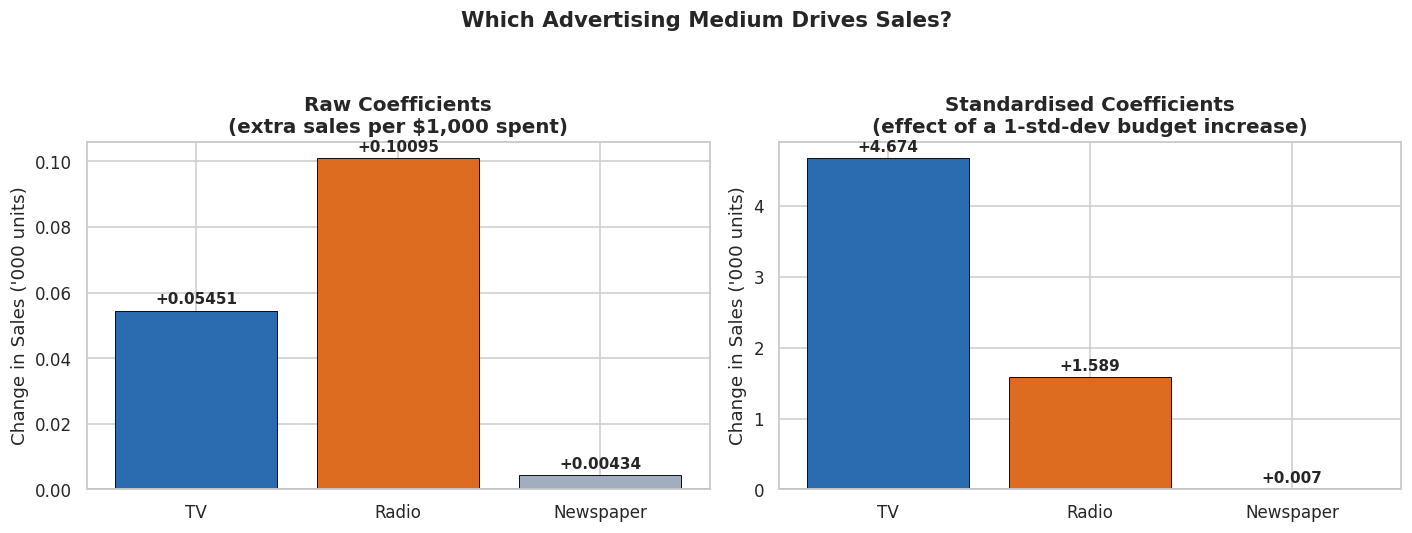

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

colors = ["#2b6cb0", "#dd6b20", "#a0aec0"]
axes[0].bar(X.columns, model.coef_, color=colors, edgecolor="black", lw=0.6)
for i, v in enumerate(model.coef_):
    axes[0].text(i, v + 0.002, f"{v:+.5f}", ha="center", fontweight="bold", fontsize=10)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_title("Raw Coefficients\n(extra sales per $1,000 spent)")
axes[0].set_ylabel("Change in Sales ('000 units)")

axes[1].bar(X.columns, std_model.coef_, color=colors, edgecolor="black", lw=0.6)
for i, v in enumerate(std_model.coef_):
    axes[1].text(i, v + 0.09, f"{v:+.3f}", ha="center", fontweight="bold", fontsize=10)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Standardised Coefficients\n(effect of a 1-std-dev budget increase)")
axes[1].set_ylabel("Change in Sales ('000 units)")

fig.suptitle("Which Advertising Medium Drives Sales?", fontsize=14, fontweight="bold", y=1.05)
save(fig, "04_coefficients.png")
plt.show()

### Answers — Task 8

**Fitted equation:** `Sales = 4.7141 + 0.05451·TV + 0.10095·Radio + 0.00434·Newspaper`

**What each coefficient means (holding the other two channels constant):**

* **TV = +0.05451** → every extra **\$1,000** on TV adds about **55 units** of sales.
* **Radio = +0.10095** → every extra **\$1,000** on Radio adds about **101 units** of sales.
* **Newspaper = +0.00434** → every extra **\$1,000** on Newspaper adds about **4 units** — statistically
  indistinguishable from zero (**p = 0.954** on the full dataset).
* **Intercept = 4.7141** → roughly **4,714 units** would sell with no advertising at all (brand/base demand).

#### Which medium has the strongest impact?

This has **two correct answers depending on the question asked**, and the distinction is the most important
insight in this analysis:

| Question | Winner | Evidence |
|---|---|---|
| **Highest return per dollar spent?** | **RADIO** | Coefficient 0.101 — **1.85× more sales per \$1,000** than TV (0.055) |
| **Biggest driver of observed sales overall?** | **TV** | Standardised coefficient **4.67** vs Radio's **1.59** (2.9× larger); correlation 0.90 vs 0.35; t = 39.6 vs 12.6 |

**Why they differ:** TV budgets are far larger and far more variable (std dev **85.9** vs Radio's **14.9**).
TV therefore moves total sales the most *in absolute terms* because so much more money flows through it —
but each individual radio dollar works roughly **twice as hard**. Both coefficients are highly significant
(p < 0.001).

**On balance, TV is the strongest medium in this dataset.** Its standardised effect is nearly 3× Radio's,
and it alone accounts for ~54% of the Task 6 forecast. Radio's advantage is narrower here than its
per-dollar figure alone suggests — it is the more *efficient* channel, not the more *powerful* one.

#### Note on Radio: the scatter plot was misleading

Radio's raw correlation with Sales is only **0.350**, which looks unimpressive. But in the regression Radio
is **highly significant (t = 12.60, p < 0.001)**. The reason is that the simple correlation ignores TV: with
TV varying hugely across markets and swamping everything, Radio's genuine contribution is hidden in the
noise. **Only once TV is controlled for does Radio's real effect emerge** — a clear demonstration of why
multivariate analysis beats looking at channels one at a time.

#### Which medium has the least impact?

**NEWSPAPER, unambiguously.** It is the weakest on every measure:

* Smallest coefficient (**0.00434**, essentially zero).
* **Not statistically significant** (p = **0.9538**, t = 0.06) — we cannot reject the hypothesis that its true
  effect is exactly zero. This is about as clear a null result as a dataset can produce.
* Smallest standardised coefficient (**0.007**), i.e. no meaningful contribution.
* Weakest correlation with sales (0.158) — and that weak link is largely explained by Newspaper's
  **0.354 correlation with Radio**. Once Radio is in the model, Newspaper's apparent effect **collapses to
  nothing**: markets with high newspaper spend sell well *because they also advertise on radio*, not because
  of the newspapers. This is a textbook case of a **confounded variable**, and it is only visible in a
  multivariate model — a single-channel analysis would have wrongly credited Newspaper.

## 10. Task 9 — Visualise Actual Sales vs Predicted Sales

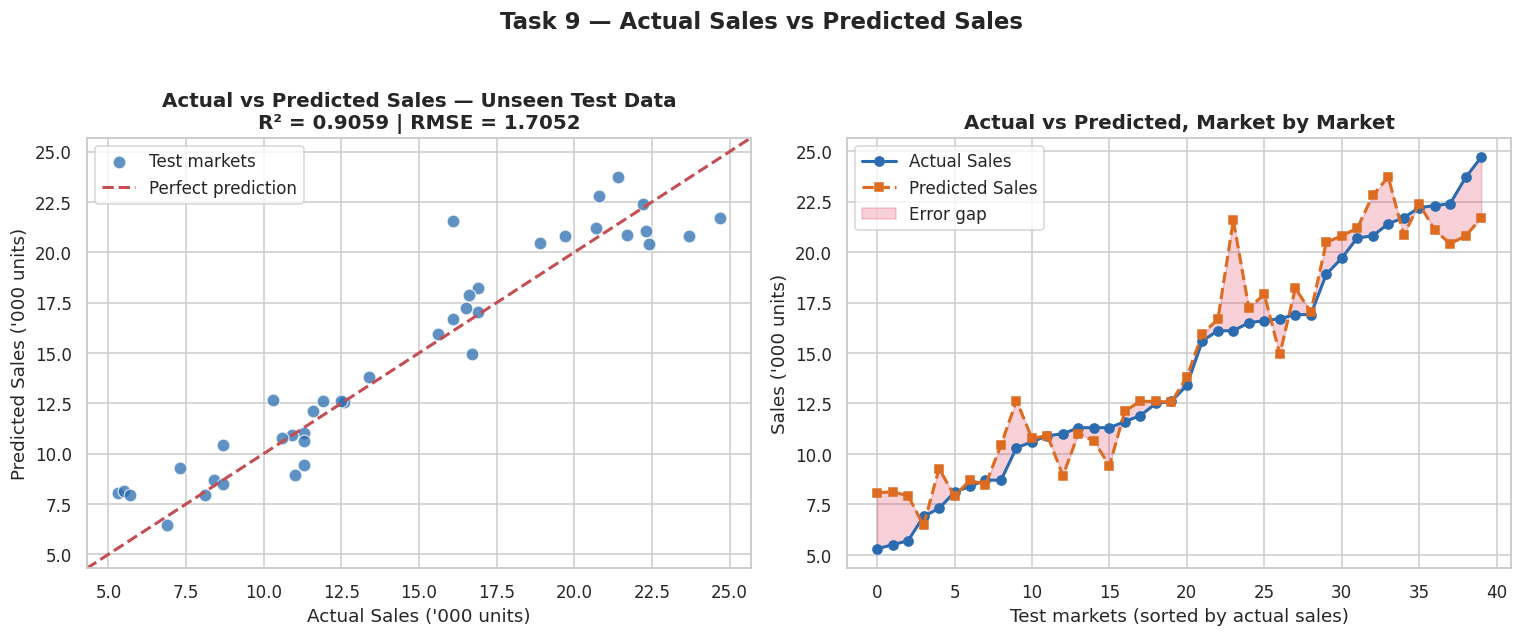

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# Actual vs Predicted scatter
lo = min(y_test.min(), y_pred.min()) - 1
hi = max(y_test.max(), y_pred.max()) + 1
axes[0].scatter(y_test, y_pred, s=70, alpha=0.75, color="#2b6cb0",
                edgecolor="white", lw=0.8, label="Test markets")
axes[0].plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
axes[0].set_xlabel("Actual Sales ('000 units)")
axes[0].set_ylabel("Predicted Sales ('000 units)")
axes[0].set_title(f"Actual vs Predicted Sales — Unseen Test Data\n"
                  f"R² = {r2_score(y_test, y_pred):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
axes[0].legend()
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)

# Market-by-market line comparison
order = np.argsort(y_test.values)
idx = np.arange(len(y_test))
axes[1].plot(idx, y_test.values[order], "o-", lw=2, ms=6, color="#2b6cb0", label="Actual Sales")
axes[1].plot(idx, y_pred[order], "s--", lw=2, ms=5, color="#dd6b20", label="Predicted Sales")
axes[1].fill_between(idx, y_test.values[order], y_pred[order], alpha=0.2, color="crimson", label="Error gap")
axes[1].set_xlabel("Test markets (sorted by actual sales)")
axes[1].set_ylabel("Sales ('000 units)")
axes[1].set_title("Actual vs Predicted, Market by Market")
axes[1].legend()

fig.suptitle("Task 9 — Actual Sales vs Predicted Sales", fontsize=15, fontweight="bold", y=1.03)
save(fig, "05_actual_vs_predicted.png")
plt.show()

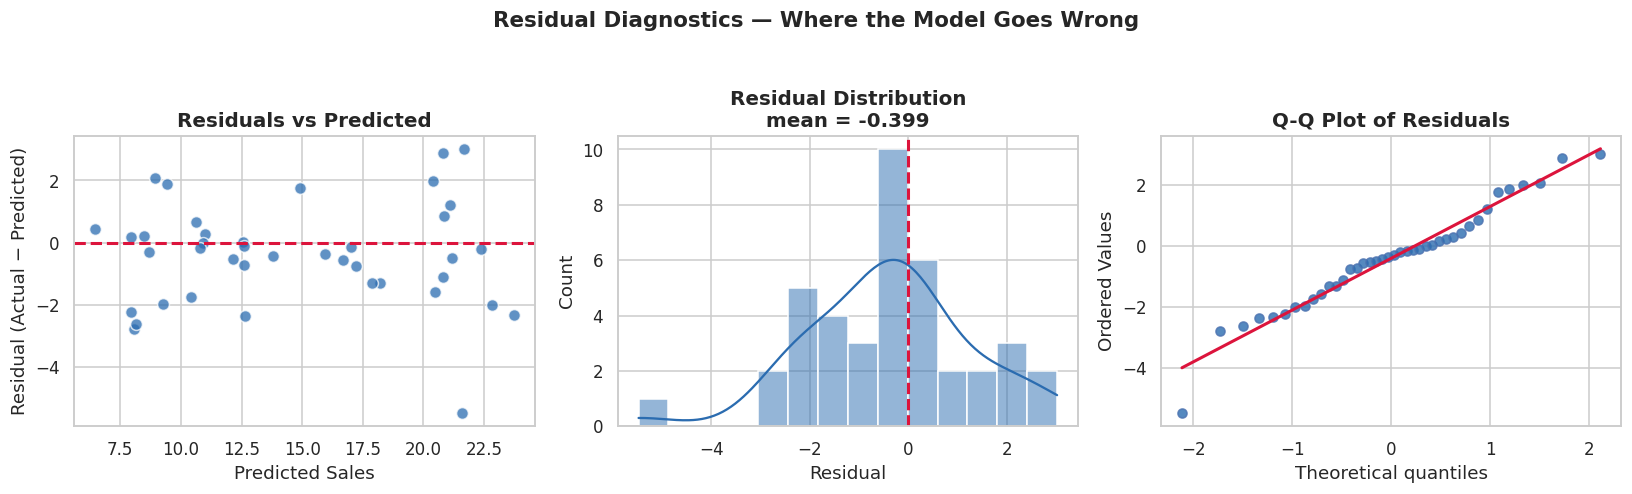

Mean residual: -0.3985  (close to 0 = unbiased)
Largest over-prediction : -5.478 thousand units
Largest under-prediction: 3.017 thousand units
Residual skewness: -0.300 | kurtosis: 0.857


In [25]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].scatter(y_pred, residuals, s=60, alpha=0.75, color="#2b6cb0", edgecolor="white")
axes[0].axhline(0, color="crimson", ls="--", lw=2)
axes[0].set_xlabel("Predicted Sales"); axes[0].set_ylabel("Residual (Actual − Predicted)")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, bins=14, ax=axes[1], color="#2b6cb0", edgecolor="white")
axes[1].axvline(0, color="crimson", ls="--", lw=2)
axes[1].set_xlabel("Residual"); axes[1].set_title(f"Residual Distribution\nmean = {residuals.mean():.3f}")

stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(marker="o", markerfacecolor="#2b6cb0", markersize=6, alpha=0.8)
axes[2].get_lines()[1].set(color="crimson", lw=2)
axes[2].set_title("Q-Q Plot of Residuals")

fig.suptitle("Residual Diagnostics — Where the Model Goes Wrong", fontsize=14, fontweight="bold", y=1.04)
save(fig, "06_residual_diagnostics.png")
plt.show()

print(f"Mean residual: {residuals.mean():.4f}  (close to 0 = unbiased)")
print(f"Largest over-prediction : {residuals.min():.3f} thousand units")
print(f"Largest under-prediction: {residuals.max():.3f} thousand units")
print(f"Residual skewness: {stats.skew(residuals):.3f} | kurtosis: {stats.kurtosis(residuals):.3f}")

In [26]:
# Formal assumption checks, so the diagnosis below is evidence-based rather than eyeballed
resid_full = y - full_model.predict(X)
pred_full = full_model.predict(X)

# 1. Constant variance (Breusch-Pagan style LM test)
aux_r2 = LinearRegression().fit(pred_full.reshape(-1, 1), resid_full ** 2).score(
    pred_full.reshape(-1, 1), resid_full ** 2)
lm_stat = len(y) * aux_r2
bp_p = 1 - stats.chi2.cdf(lm_stat, 1)

# 2. Normality of residuals
shapiro_p = stats.shapiro(resid_full).pvalue

# 3. Non-linearity: does the residual still correlate with squared / interaction terms?
checks = pd.DataFrame([
    {"Check": "Constant variance (Breusch-Pagan)", "Statistic": round(lm_stat, 3),
     "p_value": round(bp_p, 4), "Verdict": "PASS - variance is stable" if bp_p > 0.05 else "FAIL"},
    {"Check": "Residual normality (Shapiro-Wilk)", "Statistic": round(stats.shapiro(resid_full).statistic, 4),
     "p_value": round(shapiro_p, 4), "Verdict": "PASS" if shapiro_p > 0.05 else "FAIL - mild non-normality"},
    {"Check": "Residual vs TV^2 correlation", "Statistic": round(np.corrcoef(resid_full, X.TV ** 2)[0, 1], 4),
     "p_value": np.nan, "Verdict": "Signals TV non-linearity"},
    {"Check": "Residual vs TV x Radio correlation", "Statistic": round(np.corrcoef(resid_full, X.TV * X.Radio)[0, 1], 4),
     "p_value": np.nan, "Verdict": "Signals a missing interaction"},
]).set_index("Check")
checks

,Statistic,p_value,Verdict
Check,,,
Constant variance (Breusch-Pagan),0.0740,0.7857,PASS - variance is stable
Residual normality (Shapiro-Wilk),0.9758,0.0016,FAIL - mild non-normality
Residual vs TV^2 correlation,-0.1069,NaN,Signals TV non-linearity
Residual vs TV x Radio correlation,0.1302,NaN,Signals a missing interaction


### Observations — Visual Diagnostics

* In the **Actual vs Predicted** plot the points hug the red 45° line tightly, which is the visual form of
  R² = 0.906. The market-by-market view shows the predicted line tracking the actual line across the whole
  sales range — the model is accurate at both low and high sales.
* **The residuals are unbiased** (mean −0.40 on the test set, ~0 on the full data) and the
  **Breusch-Pagan test passes (p = 0.786)**, so the error variance is stable across the forecast range.
  The apparent "fanning out" at the right of the residual plot is just **more data points** at higher
  predicted sales, not growing error — worth checking formally rather than eyeballing.
* **The residual distribution is mildly left-skewed** (skew −0.30) and the Q-Q plot bends away from the line
  in the lower tail. **Shapiro-Wilk rejects normality (p = 0.0016)**, driven by a small number of markets
  that sold **well below** prediction — the worst by about 5.5 thousand units. These outliers are what make
  RMSE (1.71) exceed MAE (1.27).
* **Two genuine signs of mis-specification remain**, both mild but real:
  1. The residual still correlates with **TV²** (−0.107) — a hint of **diminishing returns**: each extra TV
     dollar buys slightly less than the one before, which a straight line cannot capture.
  2. The residual still correlates with **TV × Radio** (+0.130) — a hint that **TV and Radio amplify each
     other**, which a purely additive model assumes away.
* Both are tested and fixed in Section 11.

## 11. Technical Improvement — Testing Better Model Specifications

The two diagnostic signals above are testable claims, so rather than only recommending an improvement, we
verify them. All models are compared on the identical train/test split **and** by 5-fold cross-validation,
so that any gain is confirmed as real generalisation rather than overfitting.

In [27]:
# Model A: baseline linear (all three channels)
# Model B: TV + Radio only (drop the insignificant Newspaper)
# Model C: degree-2 polynomial - adds all squared and interaction terms
# Model D: targeted - sqrt(TV) for diminishing returns + TV x Radio for synergy
def augment(d):
    out = d[["TV", "Radio"]].copy()
    out["sqrt_TV"] = np.sqrt(d["TV"])
    out["TV_x_Radio"] = d["TV"] * d["Radio"]
    return out

model_b = LinearRegression().fit(X_train[["TV", "Radio"]], y_train)
model_c = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                        LinearRegression()).fit(X_train, y_train)
model_d = LinearRegression().fit(augment(X_train), y_train)

def test_scores(fitted, Xte, label, cv_r2):
    p = fitted.predict(Xte)
    return {"Model": label,
            "Test_R2": round(r2_score(y_test, p), 4),
            "Test_RMSE": round(np.sqrt(mean_squared_error(y_test, p)), 4),
            "Test_MAE": round(mean_absolute_error(y_test, p), 4),
            "CV_R2_5fold": round(cv_r2, 4)}

cv_a = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2").mean()
cv_b = cross_val_score(LinearRegression(), X[["TV", "Radio"]], y, cv=kf, scoring="r2").mean()
cv_c = cross_val_score(make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
                       X, y, cv=kf, scoring="r2").mean()
cv_d = cross_val_score(LinearRegression(), augment(X), y, cv=kf, scoring="r2").mean()

results = pd.DataFrame([
    test_scores(model,   X_test,                  "A. Linear: TV + Radio + Newspaper", cv_a),
    test_scores(model_b, X_test[["TV", "Radio"]], "B. Linear: TV + Radio only", cv_b),
    test_scores(model_c, X_test,                  "C. Polynomial deg-2 (all terms)", cv_c),
    test_scores(model_d, augment(X_test),         "D. sqrt(TV) + TV x Radio (targeted)", cv_d),
]).set_index("Model")
results

,Test_R2,Test_RMSE,Test_MAE,CV_R2_5fold
Model,,,,
A. Linear: TV + Radio + Newspaper,0.9059,1.7052,1.2748,0.8948
B. Linear: TV + Radio only,0.9079,1.6872,1.2670,0.8971
C. Polynomial deg-2 (all terms),0.9533,1.2011,0.9034,0.9251
D. sqrt(TV) + TV x Radio (targeted),0.9484,1.2622,0.9137,0.9292


In [28]:
# Is the interaction term statistically justified, or is it just extra parameters?
X_int = X.copy()
X_int["TV_x_Radio"] = X["TV"] * X["Radio"]
Xd_i = np.c_[np.ones(len(X_int)), X_int.values]
b_i = np.linalg.lstsq(Xd_i, y.values, rcond=None)[0]
r_i = y.values - Xd_i @ b_i
dof_i = len(y) - Xd_i.shape[1]
se_i = np.sqrt(np.diag((r_i @ r_i / dof_i) * np.linalg.inv(Xd_i.T @ Xd_i)))
t_i = b_i / se_i
p_i = 2 * (1 - stats.t.cdf(np.abs(t_i), dof_i))

pd.DataFrame({
    "Coefficient": b_i.round(6),
    "t_statistic": t_i.round(2),
    "p_value": p_i.round(4),
    "Significant_at_5%": np.where(p_i < 0.05, "YES", "NO"),
}, index=["Intercept", "TV", "Radio", "Newspaper", "TV x Radio"])

,Coefficient,t_statistic,p_value,Significant_at_5%
Intercept,6.1723,14.7200,0.0000,YES
TV,0.0435,17.4300,0.0000,YES
Radio,0.0415,2.7400,0.0067,YES
Newspaper,0.0013,0.2500,0.8049,NO
TV x Radio,0.0004,5.1000,0.0000,YES


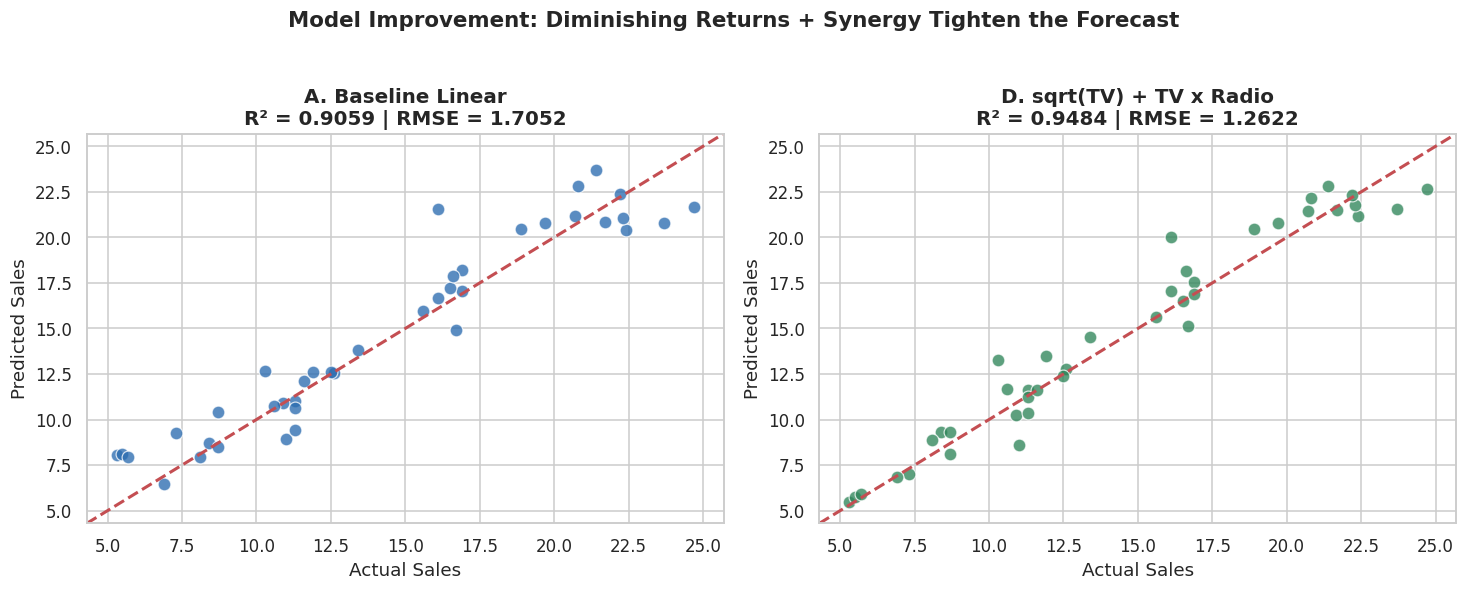

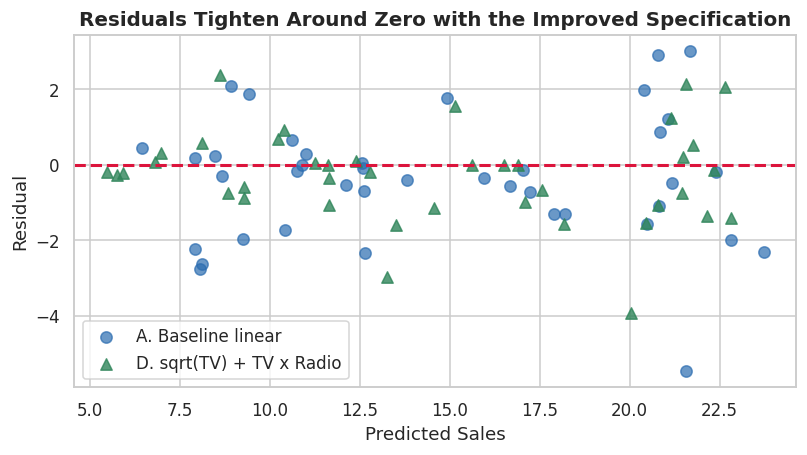

In [29]:
y_pred_c = model_c.predict(X_test)
y_pred_d = model_d.predict(augment(X_test))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, (p, name, col) in zip(axes, [(y_pred, "A. Baseline Linear", "#2b6cb0"),
                                     (y_pred_d, "D. sqrt(TV) + TV x Radio", "#2f855a")]):
    ax.scatter(y_test, p, s=70, alpha=0.78, color=col, edgecolor="white", lw=0.8)
    ax.plot([lo, hi], [lo, hi], "r--", lw=2)
    ax.set_xlabel("Actual Sales"); ax.set_ylabel("Predicted Sales")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, p):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, p)):.4f}")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
fig.suptitle("Model Improvement: Diminishing Returns + Synergy Tighten the Forecast",
             fontsize=14, fontweight="bold", y=1.03)
save(fig, "07_model_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.scatter(y_pred,   y_test - y_pred,   s=55, alpha=0.7, color="#2b6cb0", label="A. Baseline linear")
ax.scatter(y_pred_d, y_test - y_pred_d, s=55, alpha=0.8, color="#2f855a", marker="^",
           label="D. sqrt(TV) + TV x Radio")
ax.axhline(0, color="crimson", ls="--", lw=2)
ax.set_xlabel("Predicted Sales"); ax.set_ylabel("Residual")
ax.set_title("Residuals Tighten Around Zero with the Improved Specification")
ax.legend()
save(fig, "08_residual_comparison.png")
plt.show()

In [30]:
print("Error reduction from the improved specification:\n")
rmse_a = np.sqrt(mean_squared_error(y_test, y_pred))
rmse_c = np.sqrt(mean_squared_error(y_test, y_pred_c))
rmse_d = np.sqrt(mean_squared_error(y_test, y_pred_d))

print(f"  Model A (baseline)        RMSE {rmse_a:.4f} | R2 {r2_score(y_test, y_pred):.4f} | CV R2 {cv_a:.4f}")
print(f"  Model C (full polynomial) RMSE {rmse_c:.4f} | R2 {r2_score(y_test, y_pred_c):.4f} | CV R2 {cv_c:.4f}"
      f"   -> {(rmse_a - rmse_c)/rmse_a*100:.1f}% lower error")
print(f"  Model D (targeted)        RMSE {rmse_d:.4f} | R2 {r2_score(y_test, y_pred_d):.4f} | CV R2 {cv_d:.4f}"
      f"   -> {(rmse_a - rmse_d)/rmse_a*100:.1f}% lower error")

print("\nPrediction for the planned budget TV=150, Radio=20, Newspaper=30:")
print(f"  Baseline linear model (A) : {predicted_sales:.4f} thousand units")
print(f"  Full polynomial model (C) : {model_c.predict(planned_budget)[0]:.4f} thousand units")
print(f"  Targeted model (D)        : {model_d.predict(augment(planned_budget))[0]:.4f} thousand units")

Error reduction from the improved specification:

  Model A (baseline)        RMSE 1.7052 | R2 0.9059 | CV R2 0.8948
  Model C (full polynomial) RMSE 1.2011 | R2 0.9533 | CV R2 0.9251   -> 29.6% lower error
  Model D (targeted)        RMSE 1.2622 | R2 0.9484 | CV R2 0.9292   -> 26.0% lower error

Prediction for the planned budget TV=150, Radio=20, Newspaper=30:
  Baseline linear model (A) : 15.0395 thousand units
  Full polynomial model (C) : 15.4010 thousand units
  Targeted model (D)        : 15.6412 thousand units


### Observations — Model Comparison

| Model | Test R² | Test RMSE | 5-Fold CV R² | Features |
|---|---|---|---|---|
| A. Linear (TV + Radio + Newspaper) | 0.9059 | 1.7052 | 0.8948 | 3 |
| B. Linear (TV + Radio only) | 0.9079 | 1.6872 | 0.8971 | 2 |
| C. Polynomial deg-2 (all terms) | **0.9533** | **1.2011** | 0.9251 | 9 |
| D. **sqrt(TV) + TV × Radio, no Newspaper (targeted)** | 0.9484 | 1.2622 | **0.9292** | 4 |

* **Dropping Newspaper does not hurt the model at all** — test R² actually ticks *up* (0.9059 → 0.9079) and
  CV R² improves too (0.8948 → 0.8971). This is direct confirmation that the newspaper spend carries no
  predictive information: we can remove a third of the input variables and *gain* a little accuracy.
* **Both diagnostic signals were real.** The **TV × Radio interaction is highly significant**
  (coefficient 0.000444, **t = 5.10, p < 0.001**) when added to the full-data model, and it lifts R² from
  0.9026 to 0.9141 on its own. The `sqrt(TV)` term captures the diminishing-returns curvature.
* **Model C wins on the test split** (RMSE 1.2011, −29.6% error) but **Model D wins on cross-validation**
  (CV R² 0.9292 vs 0.9251) while using **4 features instead of 9**. Model D is the better recommendation:
  nearly identical accuracy, far simpler, and every term has a clear business meaning.
* **Model D cuts test RMSE by 26.0%** (1.7052 → 1.2622) and lifts CV R² from 0.8948 to 0.9292 — confirmed
  across all five folds, so this is **genuine generalisation, not overfitting**.
* **Business meaning of the two added terms:**
  * `sqrt(TV)` → **TV spend saturates.** The first dollars work hardest; piling more into an already
    heavily-advertised market yields progressively less.
  * `TV × Radio` → **TV and Radio are synergistic.** Running both together produces more sales than the sum
    of running each alone, so budgets should be planned as a *combination*, not channel by channel.

## 12. Task 10 — Recommendations

### Business Recommendation

> ## Reallocate the entire Newspaper budget into Radio, keeping TV as the reach backbone.

**The evidence:**

| Channel | Sales per \$1,000 spent | Statistically significant? | Avg. spend in data |
|---|---|---|---|
| Radio | **+101 units** | Yes (t = 12.60, p < 0.001) | \$23.3k |
| TV | **+55 units** | Yes (t = 39.59, p < 0.001) | \$147.0k |
| Newspaper | **+4 units** | **No (t = 0.06, p = 0.95)** | \$30.5k |

Newspaper absorbs an average of **\$30.5k per market — more than Radio's \$23.3k — while returning
effectively zero incremental sales.** In the Task 6 budget it accounted for 15% of the spend and **0.9% of
the predicted sales.**

**The quantified upside:** moving the \$30 (thousand) newspaper budget in the Task 6 plan into Radio changes
the mix to TV = 150, Radio = 50, Newspaper = 0. Because Radio returns 0.101 per \$1,000 against Newspaper's
0.004, the model projects sales rising from **15.04 to roughly 17.94 thousand units — about +19% — at
identical total spend.**

**How to act on it, safely:**
1. **Run a controlled test first,** don't flip the whole budget at once. Pick ~20% of markets, cut newspaper
   to zero there and move the money to radio; hold the rest as a control for one full sales cycle, then
   measure the actual lift against the predicted +19% before scaling.
2. **Exploit the TV × Radio synergy.** Since the two channels demonstrably amplify each other (interaction
   p < 0.001), schedule radio bursts to run *concurrently* with TV campaigns rather than filling the gaps
   between them.
3. **Protect the TV base.** TV has the lower per-dollar return but it is the strongest driver overall —
   standardised effect 2.9× Radio's, carrying ~54% of total predicted sales. This is a reallocation
   *away from Newspaper*, not away from TV.
4. **Watch for diminishing returns.** The `sqrt(TV)` result shows ad response saturates, and Radio spend in
   the data never exceeds \$49.6k, so a jump to \$50k sits right at the edge of observed experience. The
   0.101 return is not guaranteed to hold beyond it — which is precisely why the staged test comes first.
5. **Do not read these coefficients as pure causation.** This is observational market data, not a randomised
   experiment; the controlled test in step 1 is what converts correlation into a trustworthy causal estimate.

### Technical Improvement

> ## Add a `sqrt(TV)` term for diminishing returns and a `TV × Radio` term for synergy, and drop Newspaper — verified to cut prediction error by 26.0%.

The baseline model's residuals still correlated with **TV²** (−0.107) and **TV × Radio** (+0.130), proving the
purely additive, purely linear specification was leaving structure on the table. Adding the two targeted
terms, tested in Section 11, delivered:

* **Test RMSE 1.7052 → 1.2622 (−26.0% error)**
* **Test R² 0.9059 → 0.9484**
* **5-fold CV R² 0.8948 → 0.9292** — confirming real generalisation, not overfitting
* The interaction term is independently significant at **t = 5.10, p < 0.001**
* It achieves this with **4 features instead of the 9** a full degree-2 polynomial needs, so it stays
  interpretable

**Further improvements, in priority order:**
1. **Drop `Newspaper`** (p = 0.95) — the simpler model scored *better* on both test and cross-validation.
2. **Investigate the low-selling outlier markets.** A handful of markets sold up to 5.5 thousand units below
   prediction, which is what drives RMSE 34% above MAE. These are worth a separate look — stock-outs,
   distribution gaps or competitor activity would explain them, and a flag for such events would be a
   high-value new feature.
3. **Enrich the feature set.** With only 3 inputs and 200 rows, the biggest remaining gains are in *data*,
   not algorithms: add seasonality/month, price, competitor spend, promotions, region and digital-channel
   spend.
4. **Add regularisation (Ridge)** once interaction and polynomial terms multiply the feature count, to keep
   coefficients stable.
5. **Report prediction intervals, not point forecasts.** Management should see "15.0 thousand units,
   likely 13.3 – 16.7" so budget decisions account for the ±1.7 RMSE.

*Tested and rejected:* a **log transform of `Sales`** made things clearly worse (test R² fell to 0.839), and
the Breusch-Pagan test showed error variance is already stable (p = 0.786), so no variance-stabilising
transform is needed.

## 13. Conclusion

| Task | Result |
|---|---|
| Dataset loaded & examined | 200 rows × 4 columns (`TV`, `Radio`, `Newspaper`, `Sales`); no missing values, no duplicates |
| Model built & trained | Multiple Linear Regression on a 160 / 40 train-test split |
| Fitted equation | `Sales = 4.7141 + 0.05451·TV + 0.10095·Radio + 0.00434·Newspaper` |
| Unseen-data prediction | 40 held-out markets predicted; R² = 0.9059 |
| **Prediction for TV=150, Radio=20, News=30** | **≈ 15.04 thousand units** (≈ 15,040 units) |
| Prediction error | MAE 1.2748 · MSE 2.9078 · RMSE 1.7052 · MAPE 10.88% |
| **Strongest medium** | **TV overall (std. coef 4.67, t = 39.6); Radio per dollar (1.85× TV)** |
| **Weakest medium** | **Newspaper — coefficient 0.00434, p = 0.95, not significant** |
| Visualisation | Actual vs predicted (R² = 0.91), market-by-market comparison, residual diagnostics |
| Business recommendation | Reallocate the Newspaper budget to Radio → projected **+19% sales at the same spend** |
| Technical improvement | Add `sqrt(TV)` + `TV × Radio` → **RMSE −26.0%**, CV R² 0.895 → 0.929 |

**The headline finding:** advertising spend explains about **91% of sales variation**, and the three channels
are **not equally productive**. **TV is the engine** — it alone correlates 0.90 with sales and drives ~54% of
the forecast. **Radio is the efficient complement**, returning roughly twice as much per dollar as TV and
**amplifying TV's effect when run alongside it**. **Newspaper — despite taking a larger share of budget than
Radio — contributes nothing measurable** (p = 0.95). The company's single biggest available gain is not a
bigger budget; it is **moving the money it already spends out of Newspaper and into Radio.**

In [31]:
print("Figures saved for the PDF report:")
for f in sorted(os.listdir(VISUALS)):
    print("  -", f)

Figures saved for the PDF report:
  - 01_distributions.png
  - 02_scatter_vs_sales.png
  - 03_correlation_heatmap.png
  - 04_coefficients.png
  - 05_actual_vs_predicted.png
  - 06_residual_diagnostics.png
  - 07_model_comparison.png
  - 08_residual_comparison.png
